Exploratory Analysis

In [87]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path 
import seaborn as sns

In [88]:
from pathlib import Path

root = Path(".").resolve()
data = root/'data'
raw = data/'raw'
processed = data/'processed'
out_ch = root/'outputs'/'charts'
out_tb = root/'outputs'/'tables'
out_ch.mkdir(parents=True, exist_ok=True)
out_tb.mkdir(parents=True, exist_ok=True)

In [89]:
plt.rcParams.update({"figure.dpi": 150})
sns.set(style="whitegrid")

In [90]:
merged = pd.read_csv(processed/'merged_orders_details.csv',parse_dates=['order_date'])
target = pd.read_excel(raw/'Sales_target_1.xlsx',parse_dates=['Month of Order Date'])
print("merged shape:",merged.shape)
merged.head()
target.head()

merged shape: (1500, 10)


,Month of Order Date,Category,Target
0,2025-04-18,Furniture,10400
1,2025-05-18,Furniture,10500
2,2025-06-18,Furniture,10600
3,2025-07-18,Furniture,10800
4,2025-08-18,Furniture,10900


In [91]:

print("Columns:", merged.columns.tolist())
print("\nNull counts:\n", merged.isna().sum().sort_values(ascending=False).head(20))
print("\nUnique orders:", merged['order_id'].nunique())
print("Unique customers:", merged.get('customer_id', pd.Series()).nunique() if 'customer_id' in merged.columns else 'no customer_id')

desc = merged.describe(include='all').T
desc.to_csv(out_tb / "merged_describe.csv")


Columns: ['order_id', 'order_date', 'customername', 'state', 'city', 'amount', 'profit', 'quantity', 'category', 'sub-category']

Null counts:
 order_id        0
order_date      0
customername    0
state           0
city            0
amount          0
profit          0
quantity        0
category        0
sub-category    0
dtype: int64

Unique orders: 500
Unique customers: no customer_id


In [92]:

if 'category' in merged.columns:
    merged['category'] = merged['category'].astype(str).str.strip()

if 'state' in merged.columns:
    merged['state'] = merged['state'].astype(str).str.title().str.strip()

merged['order_month'] = merged['order_date'].dt.to_period('M').astype(str)
if 'amount' not in merged.columns and 'revenue' in merged.columns:
    merged['amount'] = merged['revenue']

/var/folders/r4/p9whfw6x43b8g5m7n4qp05_c0000gn/T/ipykernel_19485/2552031609.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category, x='category', y='total_sales', palette='viridis')


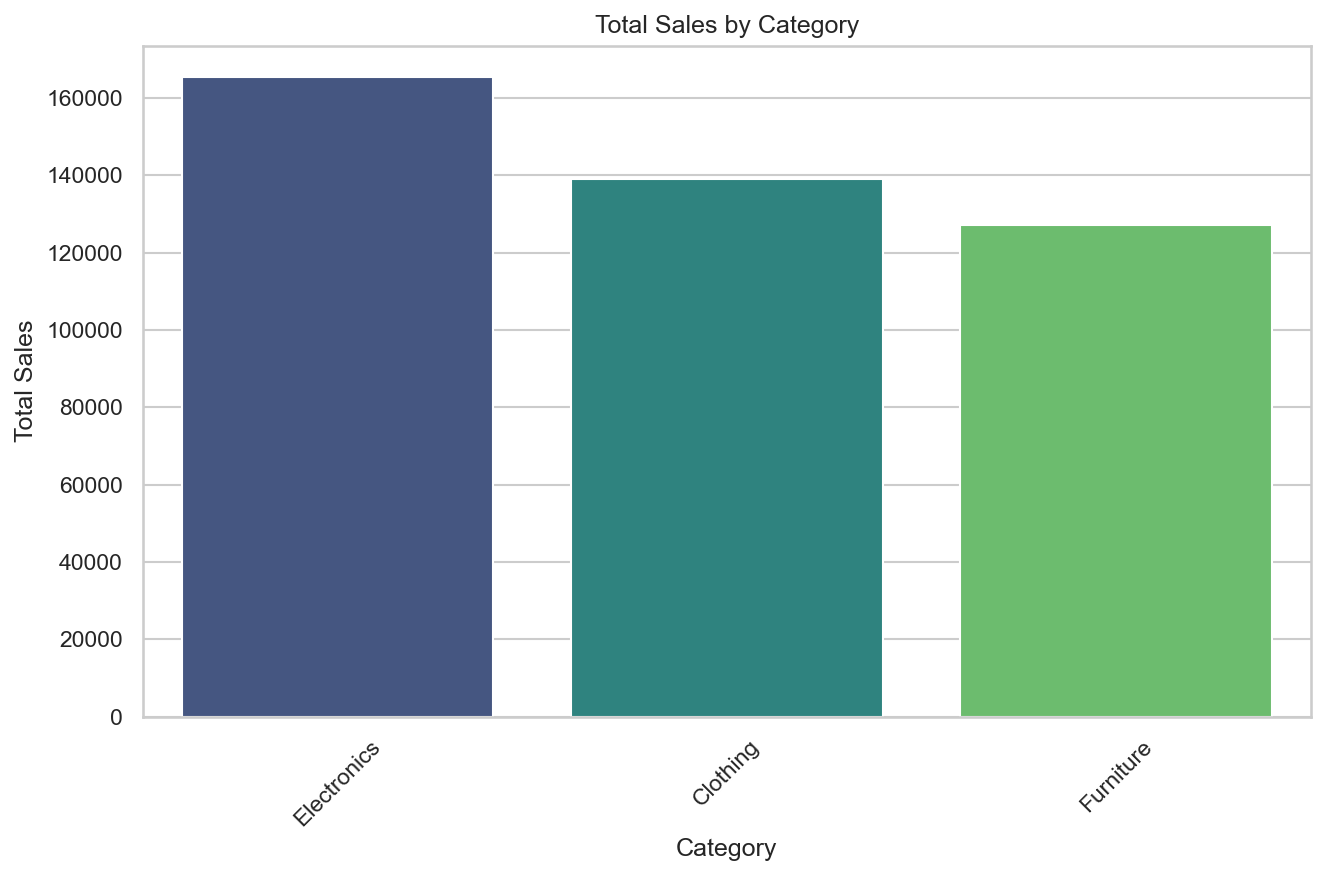

In [93]:
category = merged.groupby('category').agg(
    total_sales=('amount','sum'),
    total_profits=('profit','sum'),
    avg_pro_per_order=('profit','mean'),
    order_count = ('order_id','unique'),
    avg_order_val = ('amount','mean')
).reset_index()
category['profit_margin_percent'] = (category['total_profits'] / category['total_sales']) * 100
category = category.sort_values(by='total_sales', ascending=False)
category.to_csv(out_tb/'category_summary.csv',index=False)
plt.figure(figsize=(9,6))
sns.barplot(data=category, x='category', y='total_sales', palette='viridis')
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(out_ch/'total_sales_by_category.png')
plt.show() 


In [94]:
category.head(20)

,category,total_sales,total_profits,avg_pro_per_order,order_count,avg_order_val,profit_margin_percent
1,Electronics,165267,10494,34.071429,"[B-25601, B-25602, B-25608, B-25609, B-25610, ...",536.581169,6.349725
0,Clothing,139054,11163,11.762908,"[B-25601, B-25602, B-25603, B-25604, B-25605, ...",146.526870,8.027817
2,Furniture,127181,2298,9.456790,"[B-25601, B-25603, B-25608, B-25610, B-25612, ...",523.378601,1.806874


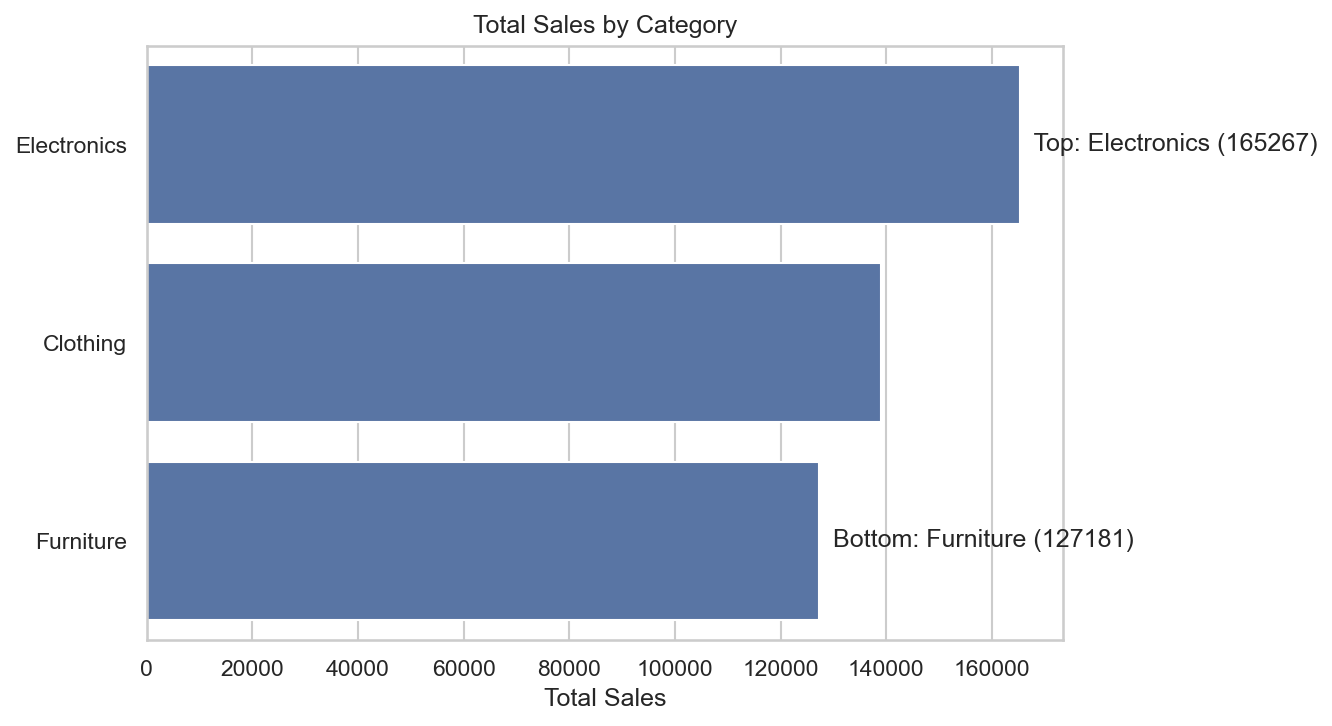

In [95]:
plt.figure(figsize=(9,5))
ax = sns.barplot(data=category, x='total_sales', y='category', order=category['category'])
ax.set_xlabel("Total Sales")
ax.set_ylabel("")
ax.set_title("Total Sales by Category")
# Annotate top and bottom
top_cat = category.iloc[0]
bot_cat = category.iloc[-1]
ax.text(top_cat['total_sales'], 0, f"  Top: {top_cat['category']} ({top_cat['total_sales']:.0f})", va='center')
ax.text(bot_cat['total_sales'], len(category)-1, f"  Bottom: {bot_cat['category']} ({bot_cat['total_sales']:.0f})", va='center')
plt.tight_layout()
plt.savefig(out_ch/ "total_sales_by_category_.png", dpi=300)
plt.show()


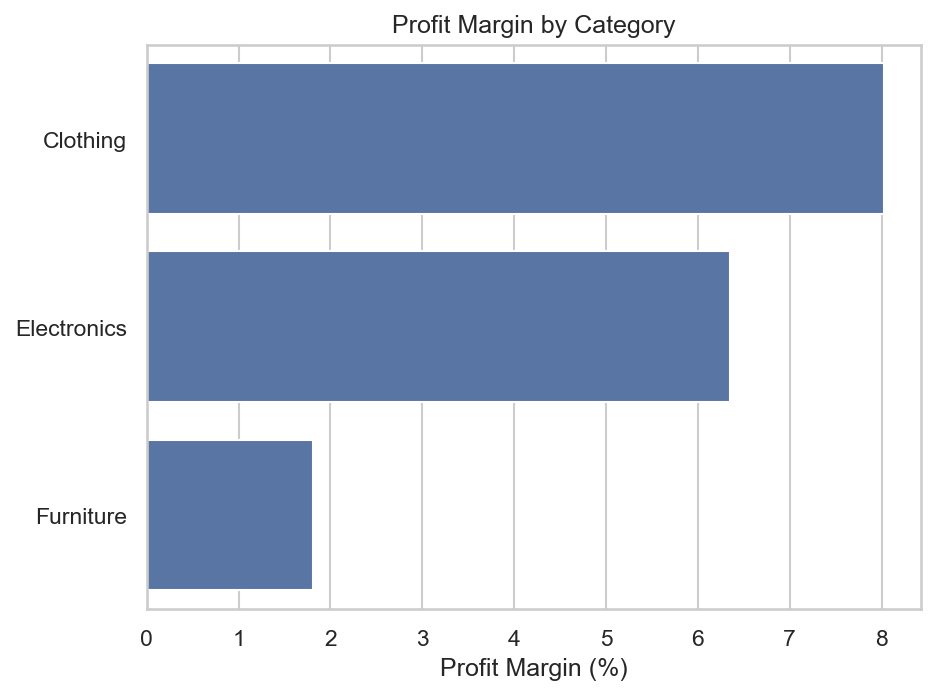

In [96]:
plt.Figure(figsize=(9,5))
cat_m = category.sort_values('profit_margin_percent',ascending=False)
plot = sns.barplot(data=cat_m, x='profit_margin_percent', y='category', order=cat_m['category'])
plot.set_xlabel("Profit Margin (%)")
plot.set_ylabel("")
plot.set_title("Profit Margin by Category")
plt.tight_layout()
plt.savefig(out_ch/"profit_margin_by_category.png", dpi=300)
plt.show()


In [97]:
furn_actual = merged[merged['category'].str.lower() =='furniture' ].groupby('order_month').agg(actual_sales = ('amount','sum')).reset_index()

In [98]:
t = target.copy()
t.columns = [c.lower().strip().replace(' ', '_') for c in t.columns]

if 'category' in t.columns:
    t = t[t['category'].str.lower() == 'furniture']


month_col = next((c for c in t.columns if 'month' in c), None)
if month_col is not None:
    t = t.rename(columns={month_col: 'month'})
    t['month'] = pd.to_datetime(t['month']).dt.to_period('M').astype(str)
else:
    t['month'] = pd.Series(dtype='object')

if 'target_sales' not in t.columns:
    numeric_cols = t.select_dtypes(include='number').columns.tolist()
    if numeric_cols:
        t = t.rename(columns={numeric_cols[0]: 'target_sales'})
    else:
        t['target_sales'] = 0

furn = pd.merge(
    t[['month', 'target_sales']].rename(columns={'month': 'order_month'}),
    furn_actual,
    on='order_month',
    how='outer'
).sort_values('order_month')

furn['target_sales'] = furn['target_sales'].fillna(0)
furn['actual_sales'] = furn['actual_sales'].fillna(0)
furn['pct_diff'] = (furn['actual_sales'] - furn['target_sales']) / furn['target_sales'].replace({0: np.nan}) * 100

furn.to_csv(out_tb / "furniture_targets_vs_actuals.csv", index=False)
furn.head()

,order_month,target_sales,actual_sales,pct_diff
0,2018-04,0.0,8121.0,NaN
1,2018-05,0.0,6220.0,NaN
2,2018-06,0.0,5532.0,NaN
3,2018-07,0.0,3483.0,NaN
4,2018-08,0.0,9538.0,NaN


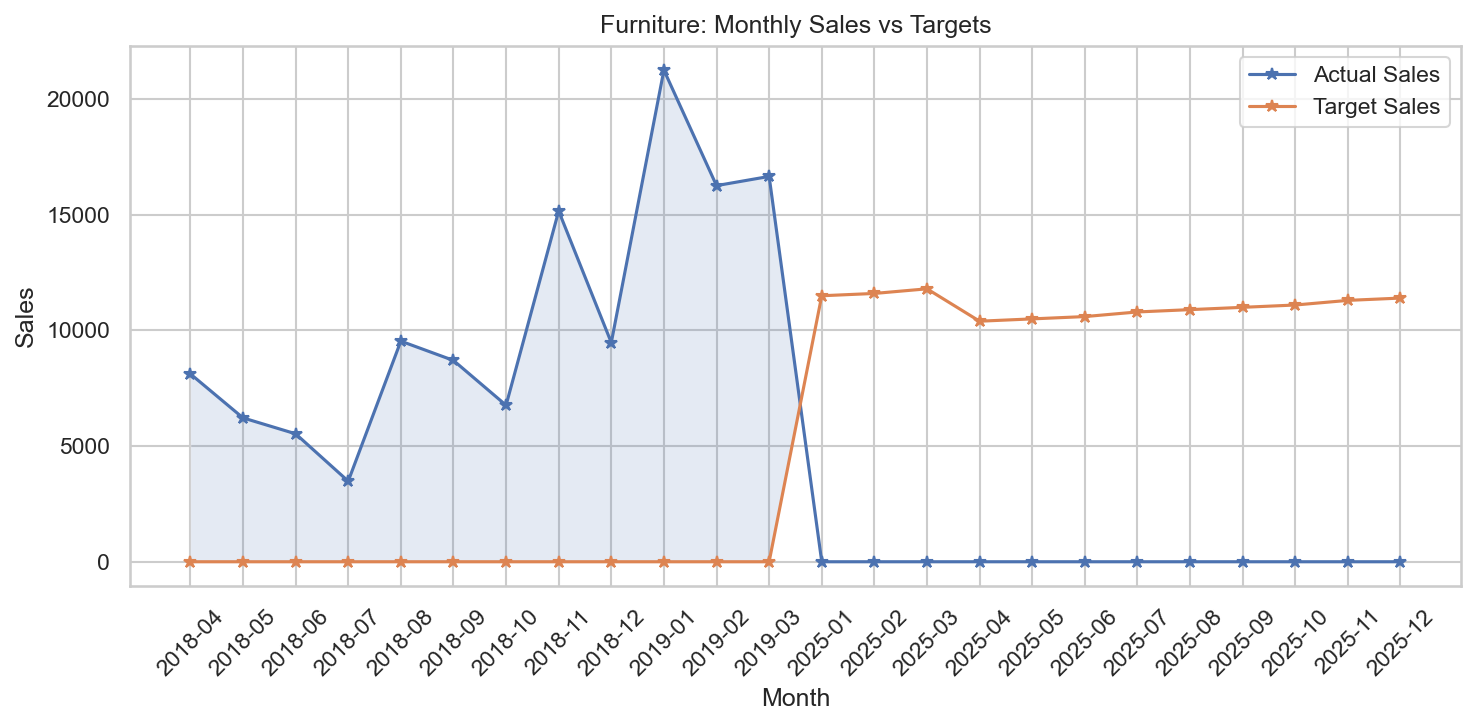

In [99]:
plt.figure(figsize=(10,5))
plt.plot(furn['order_month'], furn['actual_sales'], marker='*', label='Actual Sales')
plt.plot(furn['order_month'], furn['target_sales'], marker='*', label='Target Sales')
plt.xticks(rotation=45)
plt.fill_between(furn['order_month'], furn['actual_sales'], furn['target_sales'], where=(furn['actual_sales']>=furn['target_sales']), interpolate=True, alpha=0.15)
plt.title("Furniture: Monthly Sales vs Targets")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.savefig(out_ch / "furniture_sales_vs_targets.png", dpi=300)
plt.show()


In [100]:

states = merged.groupby('state').agg(
    total_sales = ('amount','sum'),
    order_count = ('order_id','nunique'),
    avg_profit = ('profit','mean')
).reset_index().sort_values('order_count', ascending=False)

top_5_states = states.head(5)
top_5_states.to_csv(out_tb/'top_5_states_by_orders.csv', index=False)
top_5_states


,state,total_sales,order_count,avg_profit
10,Madhya Pradesh,105140,101,16.326471
11,Maharashtra,95348,90,21.296552
14,Rajasthan,21149,32,16.986486
4,Gujarat,21058,27,5.344828
13,Punjab,16786,25,-10.150000


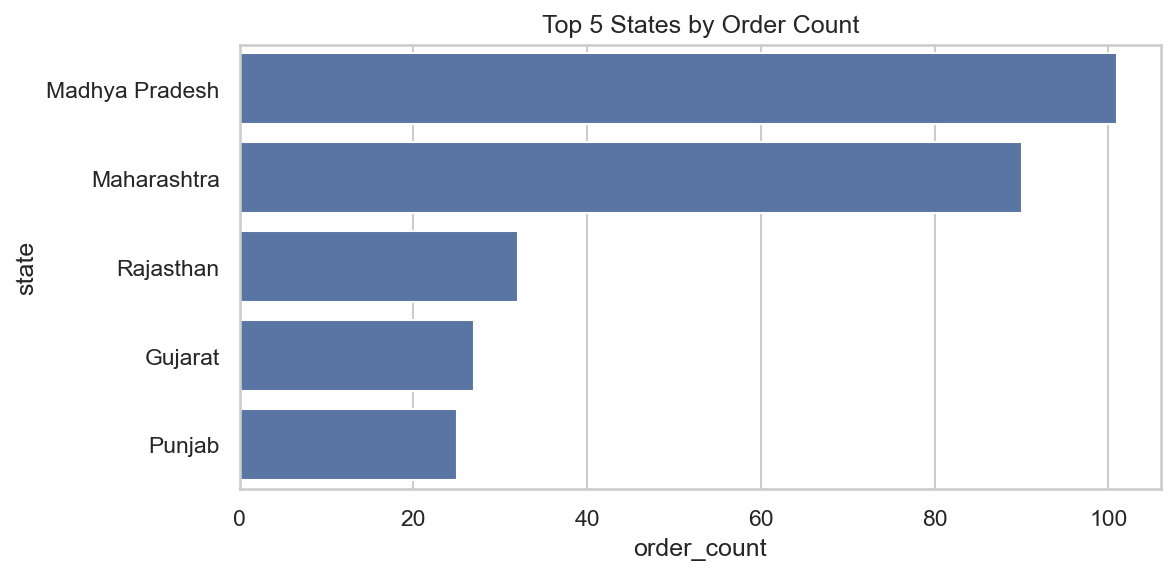

In [101]:
plt.figure(figsize=(8,4))
ax = sns.barplot(data=top_5_states, x='order_count', y='state', orient='h')
ax.set_title("Top 5 States by Order Count")
plt.tight_layout()
plt.savefig(out_ch / "top_5_states_order_count.png", dpi=300)
plt.show()


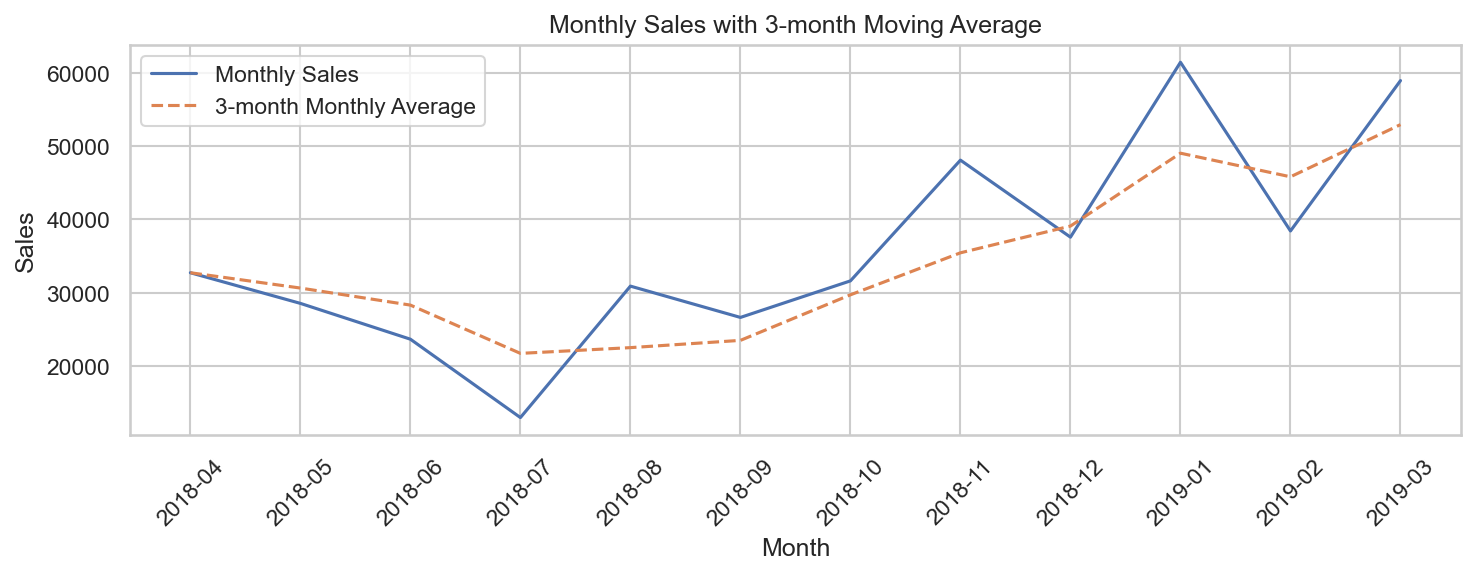

In [102]:
monthly = merged.groupby('order_month').agg(total_sales=('amount','sum')).reset_index().sort_values('order_month')
monthly['order_month_dt'] = pd.to_datetime(monthly['order_month'])
monthly = monthly.set_index('order_month_dt').asfreq('MS').fillna(0).reset_index()
monthly['ma_3'] = monthly['total_sales'].rolling(3, min_periods=1).mean()
monthly.to_csv(out_tb / "monthly_sales.csv", index=False)

plt.figure(figsize=(10,4))
plt.plot(monthly['order_month'], monthly['total_sales'], label='Monthly Sales')
plt.plot(monthly['order_month'], monthly['ma_3'], label='3-month Monthly Average', linestyle='--')
plt.xticks(rotation=45)
plt.title("Monthly Sales with 3-month Moving Average")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.savefig(out_ch / "monthly_sales_ma.png", dpi=300)
plt.show()


In [103]:
if 'discount' in merged.columns:
    merged['discount_percent'] = (merged['discount']/merged['amount'])*100
else:
    merged['discount_percent'] = np.nan
merged['profit_margin_percent'] = (merged['profit']/merged['amount'])*100


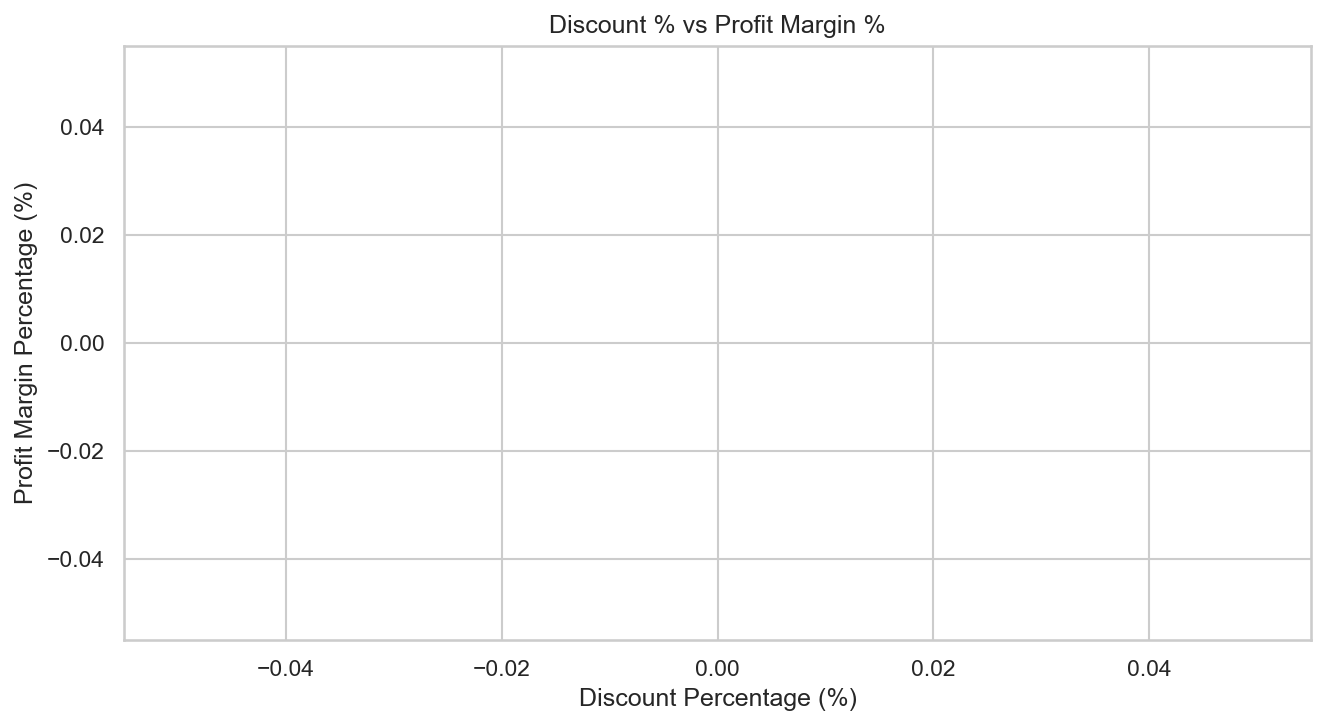

In [104]:
plt.figure(figsize=(9,5))
sns.regplot(data=merged,x='discount_percent',y='profit_margin_percent',scatter_kws={'alpha':0.5})
plt.title("Discount % vs Profit Margin %")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Profit Margin Percentage (%)")
plt.tight_layout()
plt.savefig(out_ch/'discount_vs_profit_margin.png',dpi=300)
plt.show()

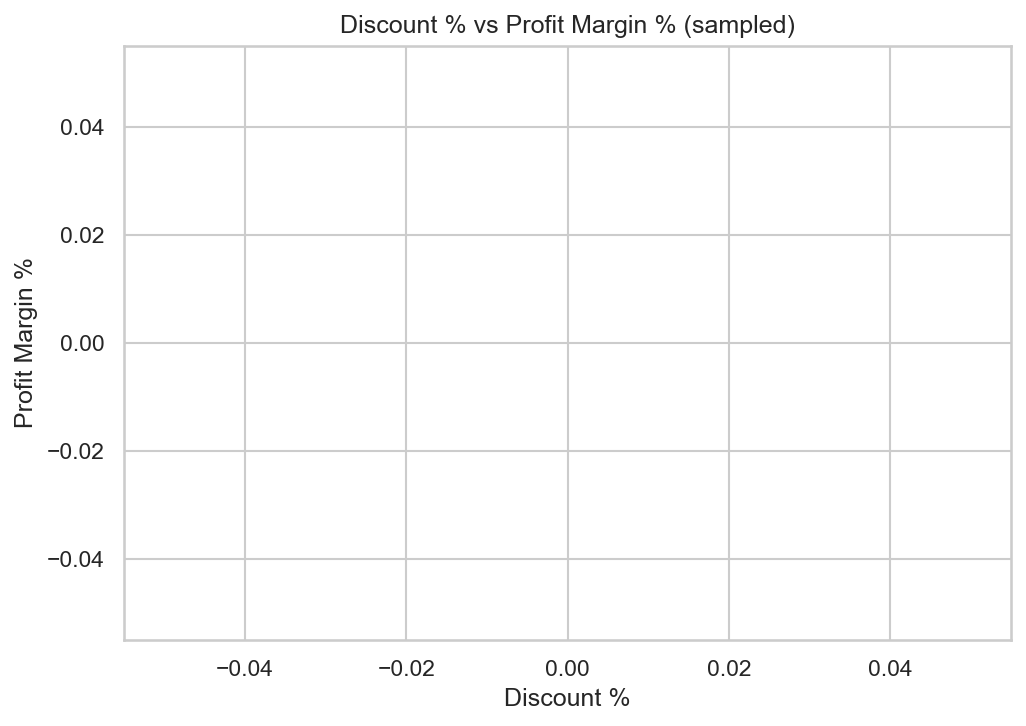

In [105]:
plt.figure(figsize=(7,5))
sns.regplot(data=merged.sample(min(len(merged), 2000)), x='discount_percent', y='profit_margin_percent', scatter_kws={'s':10}, lowess=True)
plt.xlabel("Discount %")
plt.ylabel("Profit Margin %")
plt.title("Discount % vs Profit Margin % (sampled)")
plt.tight_layout()
plt.savefig(out_ch / "discount_vs_profit_margin.png", dpi=300)
plt.show()

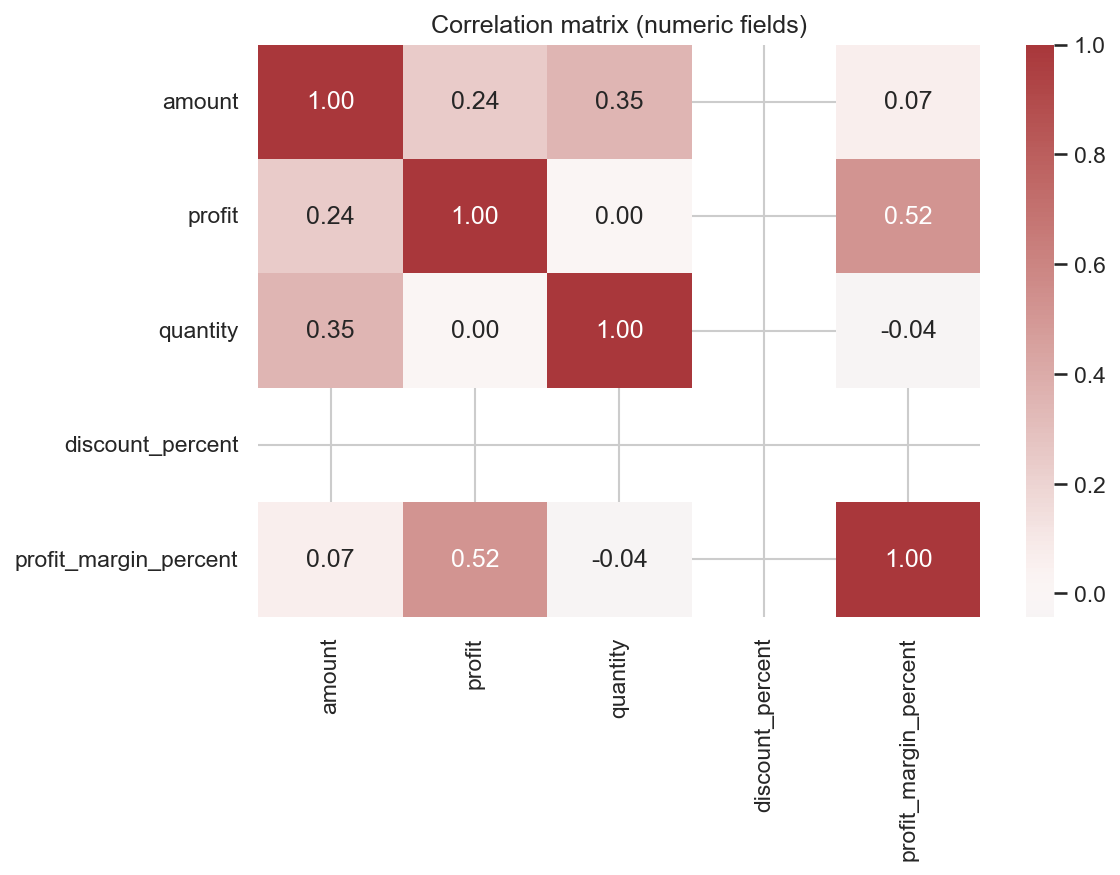

In [106]:
num_cols = merged.select_dtypes(include=[np.number]).columns.tolist()
corr = merged[num_cols].corr()
corr.to_csv(out_tb / "numeric_correlation_matrix.csv")

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix (numeric fields)")
plt.tight_layout()
plt.savefig(out_ch / "correlation_matrix.png", dpi=300)
plt.show()


In [107]:
# Save outputs for dashboards
category.to_csv(out_tb / "category_summary_for_dashboard.csv", index=False)
monthly[['order_month','total_sales','ma_3']].to_csv(out_tb / "monthly_sales_for_dashboard.csv", index=False)
states.to_csv(out_tb / "state_summary_for_dashboard.csv", index=False)


In [108]:
summary_kpis = {
    'total_sales': [merged['amount'].sum()],
    'total_profit': [merged['profit'].sum()],
    'avg_margin_pct': [(merged['profit'].sum() / merged['amount'].sum()) * 100 if merged['amount'].sum() != 0 else np.nan],
    'total_orders': [merged['order_id'].nunique()]
}
summary_df = pd.DataFrame(summary_kpis)
summary_df.to_csv(out_tb / "kpis_summary.csv", index=False)
summary_df


,total_sales,total_profit,avg_margin_pct,total_orders
0,431502,23955,5.551539,500
